# Manejo de datos desbalanceados
**Píldora · Esra Kesken · 12/11/2026**

Detectar fraudes, enfermedades o piezas defectuosas: casi siempre la clase que nos importa es **la que menos aparece**.
En este notebook vemos por qué la accuracy engaña y cuatro técnicas para solucionarlo.

> *"When one class is rare, a model can be 99 % accurate and completely useless."*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 1. Un dataset desbalanceado
Generamos 10.000 transacciones: **0 = normal**, **1 = fraude** (≈ 1,5 %).

In [2]:
X, y = make_classification(
    n_samples=10_000, n_features=10, n_informative=5,
    weights=[0.99], random_state=42
)
pd.Series(y).value_counts()

0    9853
1     147
Name: count, dtype: int64

## 2. La accuracy miente
Un "modelo tonto" que **siempre dice "normal"**, sin aprender nada.
`stratify=y` mantiene el mismo % de fraudes en train y test.

> *"Accuracy lies: this model detects zero frauds."*

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
y_pred_tonto = np.zeros_like(y_test)
accuracy_score(y_test, y_pred_tonto)

0.9853333333333333

## 3. Un modelo real (baseline)
Regresión logística sin tratar el desbalance. Miramos el **recall** de la clase 1: ¿cuántos fraudes detecta?

              precision    recall  f1-score   support

           0      0.985     1.000     0.993      2956
           1      0.000     0.000     0.000        44

    accuracy                          0.985      3000
   macro avg      0.493     0.500     0.496      3000
weighted avg      0.971     0.985     0.978      3000



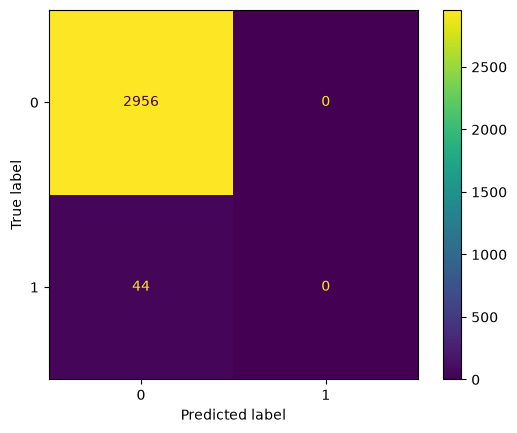

In [4]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred);

## 4. Tabla de resultados
Guardamos las métricas de cada técnica para compararlas al final.
- **Precision:** de las alarmas, ¿cuántas son fraude de verdad?
- **Recall:** de los fraudes, ¿cuántos detectamos?
- **F1:** equilibrio entre las dos.

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score

resultados = []

def evaluar(nombre, y_true, y_pred):
    resultados.append({
        "técnica": nombre,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    })
    return pd.DataFrame(resultados).round(3)

evaluar("Modelo tonto", y_test, y_pred_tonto)
evaluar("Baseline (sin tratar)", y_test, y_pred)

,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.0,0.0,0.0
1,Baseline (sin tratar),0.985,0.0,0.0,0.0


## 5. Técnica 1 · `class_weight='balanced'`
No toca los datos: castiga más los errores en la clase minoritaria.

> *"We tell the model: missing a fraud is much more expensive."*

,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058


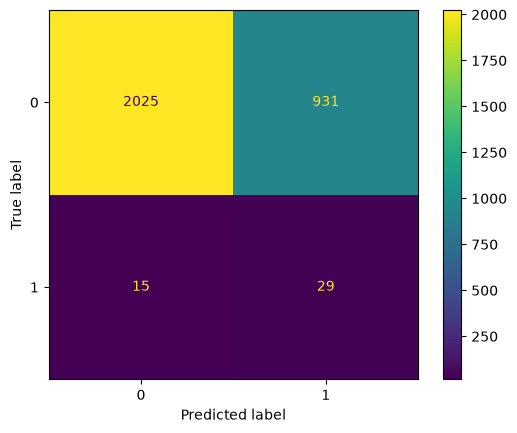

In [6]:
modelo_cw = LogisticRegression(max_iter=1000, class_weight="balanced")
modelo_cw.fit(X_train, y_train)
y_pred_cw = modelo_cw.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cw)
evaluar("class_weight='balanced'", y_test, y_pred_cw)

## 6. Técnica 2 · Undersampling
Quitamos ejemplos de la clase mayoritaria hasta igualar. Rápido, pero tira datos.

In [7]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("Antes:", pd.Series(y_train).value_counts().to_dict())
print("Después:", pd.Series(y_train_rus).value_counts().to_dict())

modelo_rus = LogisticRegression(max_iter=1000)
modelo_rus.fit(X_train_rus, y_train_rus)
y_pred_rus = modelo_rus.predict(X_test)
evaluar("Undersampling", y_test, y_pred_rus)

Antes: {0: 6897, 1: 103}
Después: {0: 103, 1: 103}


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058
3,Undersampling,0.646,0.03,0.727,0.057


## 7. Técnica 3 · SMOTE
Crea fraudes sintéticos entre fraudes reales. Solo sobre el train.

In [8]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("Antes:", pd.Series(y_train).value_counts().to_dict())
print("Después:", pd.Series(y_train_sm).value_counts().to_dict())

modelo_sm = LogisticRegression(max_iter=1000)
modelo_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = modelo_sm.predict(X_test)
evaluar("SMOTE", y_test, y_pred_sm)

Antes: {0: 6897, 1: 103}
Después: {0: 6897, 1: 6897}


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.00,0.000,0.000
1,Baseline (sin tratar),0.985,0.00,0.000,0.000
2,class_weight='balanced',0.685,0.03,0.659,0.058
3,Undersampling,0.646,0.03,0.727,0.057
4,SMOTE,0.697,0.03,0.636,0.058


## 8. Técnica 4 · Threshold (Umbral)
Cambiamos solo la frontera de decisión (0,5 por defecto). Ni el modelo ni los datos cambian.


In [9]:
proba = modelo.predict_proba(X_test)[:, 1]   # probabilidad de "fraude" del modelo baseline
print("Probabilidad máxima:", proba.max().round(3))

filas = []
for t in [0.5, 0.2, 0.1, 0.05, 0.03, 0.02]:
    y_t = (proba >= t).astype(int)
    filas.append({
        "umbral": t,
        "alarmas": y_t.sum(),
        "precision": precision_score(y_test, y_t, zero_division=0),
        "recall": recall_score(y_test, y_t),
        "f1": f1_score(y_test, y_t),
    })
pd.DataFrame(filas).round(3)

Probabilidad máxima: 0.404


,umbral,alarmas,precision,recall,f1
0,0.50,0,0.000,0.000,0.000
1,0.20,1,1.000,0.023,0.044
2,0.10,13,0.231,0.068,0.105
3,0.05,76,0.092,0.159,0.117
4,0.03,277,0.072,0.455,0.125
5,0.02,610,0.046,0.636,0.086


,técnica,accuracy,precision,recall,f1
0,Modelo tonto,0.985,0.000,0.000,0.000
1,Baseline (sin tratar),0.985,0.000,0.000,0.000
2,class_weight='balanced',0.685,0.030,0.659,0.058
3,Undersampling,0.646,0.030,0.727,0.057
4,SMOTE,0.697,0.030,0.636,0.058
5,Umbral 0.03,0.906,0.072,0.455,0.125


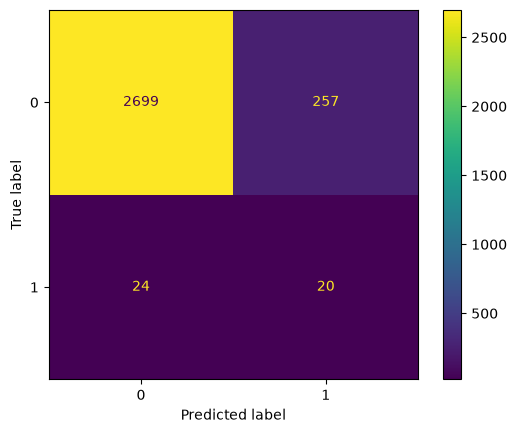

In [10]:
y_pred_t = (proba >= 0.03).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t)
evaluar("Umbral 0.03", y_test, y_pred_t)

## 9. ⚠️ Trampa: SMOTE antes del split (data leakage)
Si hacemos SMOTE antes del split, el test se llena de fraudes inventados y el resultado es falso.

In [11]:
# ❌ MAL: SMOTE sobre TODOS los datos y después el split
X_mal, y_mal = SMOTE(random_state=42).fit_resample(X, y)
X_tr_mal, X_te_mal, y_tr_mal, y_te_mal = train_test_split(
    X_mal, y_mal, test_size=0.3, stratify=y_mal, random_state=42
)
print("Fraudes en el test:", y_te_mal.sum(), "de", len(y_te_mal))

modelo_mal = LogisticRegression(max_iter=1000).fit(X_tr_mal, y_tr_mal)
y_pred_mal = modelo_mal.predict(X_te_mal)
print(classification_report(y_te_mal, y_pred_mal, digits=3))

Fraudes en el test: 2956 de 5912
              precision    recall  f1-score   support

           0      0.689     0.701     0.695      2956
           1      0.696     0.684     0.690      2956

    accuracy                          0.692      5912
   macro avg      0.693     0.692     0.692      5912
weighted avg      0.693     0.692     0.692      5912



## 10. Conclusiones

| Si… | Usa |
|---|---|
| Quieres lo más sencillo | `class_weight='balanced'` (empieza siempre por aquí) |
| Perder un caso es muy caro (fraude, enfermedad) | La técnica con más **recall** |
| Cada falsa alarma cuesta (alguien la revisa) | Ajustar el **umbral** |
| Tienes muchísimos datos | Undersampling |

**Reglas:**
1. Nunca mires solo la accuracy: mira precision, recall y F1 de la clase minoritaria.
2. Primero el split, después el remuestreo, y **solo en el train**.
3. El umbral se elige con un conjunto de **validación**, no con el test.

> *"There is no magic technique. Choose the metric that matters for your problem, then the technique."*